# Predictive Modeling Using Machine Learning: Supervised Learning & Model Evaluation

This notebook walks through a complete, leakage-free supervised learning workflow covering both **Classification** and **Regression**:
1. **Algorithms Applied:** Logistic Regression / Linear Regression (OLS), Decision Trees (unconstrained vs. regularized), and Random Forests (default and `GridSearchCV`-tuned), compared against naive baselines.
2. **Strict Validation Discipline:** Splitting into **Train (60%) / Validation (20%) / Test (20%)** *before* fitting missing-value imputers or feature scalers.
3. **Evaluation & Visualization:** Confusion matrices, ROC curves with AUC and Youden's J operating threshold, Precision-Recall curves, Actual-vs-Predicted & Residual plots, 5-fold cross-validation, 95% bootstrap confidence intervals, slice-based error analysis, and feature importances.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from predictive_modeling.data import load_builtin_classification, load_builtin_regression, split_dataset
from predictive_modeling.preprocessing import analyze_data_quality, build_preprocessor
from predictive_modeling.pipeline import run_experiment

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
print(f"Project root: {PROJECT_ROOT}")


Project root: C:\Users\HP\.gemini\antigravity\scratch\predictive-modeling-ml


### Environment Setup Check
The local package path (`src/`) is resolved dynamically so all modular loaders, preprocessors, evaluators, and plotting utilities execute reproducibly across environments.


---
## Part 1: Classification Track — Breast Cancer Diagnostic Dataset

First, we solve binary classification (`1 = Malignant`, `0 = Benign`), matching the confusion matrix and ROC/AUC evaluation concepts from the task tutorial.


In [2]:
cls_bundle = load_builtin_classification(export_csv_path=PROJECT_ROOT / "data" / "raw" / "breast_cancer.csv")
cls_quality = analyze_data_quality(cls_bundle.df, cls_bundle.target_col)

print(cls_bundle.description)
print(f"Rows: {cls_quality['n_rows']}, Features: {cls_quality['n_features']}")
print(f"Missing cells: {cls_quality['total_missing_cells']}, Duplicate rows: {cls_quality['duplicate_rows']}")
print(f"Class balance (0=Benign, 1=Malignant): {cls_quality['target_summary']}")
display(cls_bundle.df.head())


Breast Cancer Wisconsin Diagnostic dataset (569 FNA cell-nuclei samples, 30 numeric features; target diagnosis_malignant: 1=Malignant, 0=Benign).
Rows: 569, Features: 30
Missing cells: 0, Duplicate rows: 0
Class balance (0=Benign, 1=Malignant): {'0': 357, '1': 212}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,...,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis_malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,...,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,...,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,...,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,...,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,...,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### Dataset Schema & Data Quality Observations
- The dataset contains **569 samples** and **30 continuous numeric diagnostic features** computed from digitized cell nuclei images (radius, texture, perimeter, area, smoothness, concavity, etc.).
- Target `diagnosis_malignant` has **357 Benign (0)** and **212 Malignant (1)** samples (37.3% positive prevalence), making **ROC-AUC, Recall, Precision, and F1** essential alongside raw Accuracy.
- All 569 rows have valid targets, **0 missing cells**, and **0 duplicate rows** (our generic CSV preprocessing pipeline also automatically handles missing numeric/categorical features when supplied custom CSVs).


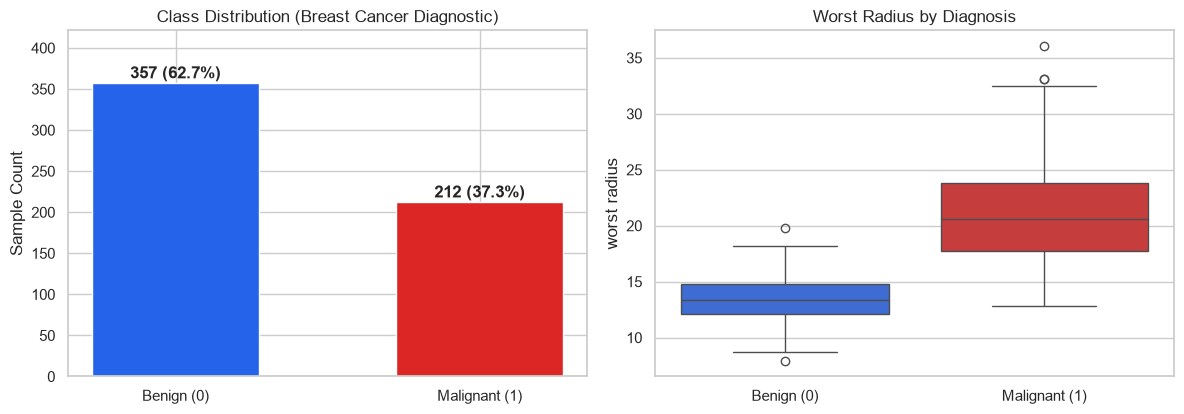

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
counts = cls_bundle.df[cls_bundle.target_col].value_counts().sort_index()
axes[0].bar(["Benign (0)", "Malignant (1)"], counts.values, color=["#2563EB", "#DC2626"], width=0.55)
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 6, f"{v} ({v/len(cls_bundle.df)*100:.1f}%)", ha="center", fontweight="bold")
axes[0].set_title("Class Distribution (Breast Cancer Diagnostic)")
axes[0].set_ylabel("Sample Count")
axes[0].set_ylim(0, max(counts.values) * 1.18)

sns.boxplot(
    data=cls_bundle.df,
    x=cls_bundle.target_col,
    y="worst radius",
    hue=cls_bundle.target_col,
    palette=["#2563EB", "#DC2626"],
    legend=False,
    ax=axes[1],
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Benign (0)", "Malignant (1)"])
axes[1].set_title("Worst Radius by Diagnosis")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()


### Exploratory Visual Analysis
The distribution of `worst radius` shows strong separation between Benign and Malignant nuclei: malignant tumors exhibit larger radii and wider variance, while overlap in the mid-range motivates threshold-aware classifiers and ROC evaluation.


In [4]:
X_cls = cls_bundle.df[cls_bundle.feature_names]
y_cls = cls_bundle.df[cls_bundle.target_col]
cls_split = split_dataset(X_cls, y_cls, task_type="classification", test_size=0.20, val_size=0.20, random_state=42)
cls_prep, cls_prep_meta = build_preprocessor(cls_split.X_train)

print(f"Split sizes -> Train: {len(cls_split.X_train)}, Val: {len(cls_split.X_val)}, Test: {len(cls_split.X_test)}")
print(f"Train positive rate: {cls_split.y_train.mean():.4f} | Val: {cls_split.y_val.mean():.4f} | Test: {cls_split.y_test.mean():.4f}")
print("Preprocessor metadata:", cls_prep_meta)


Split sizes -> Train: 341, Val: 114, Test: 114
Train positive rate: 0.3724 | Val: 0.3772 | Test: 0.3684
Preprocessor metadata: {'numeric_columns': ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension'], 'categorical_columns': [], 'dropped_all_nan_columns': [], 'numeric_missing_indicator_enabled': False, 'max_ohe_categories': 20}


### Strict Featurization Ordering Check
Splitting into **Train (341)**, **Validation (114)**, and **Test (114)** *before* fitting `ColumnTransformer` prevents data leakage: `SimpleImputer` medians and `StandardScaler` means/variances are learned exclusively from `X_train`. Stratified splitting maintains an identical ~37.2%–37.7% malignant rate across splits.


In [5]:
cls_result = run_experiment(
    cls_bundle,
    output_dir=PROJECT_ROOT / "outputs" / "classification",
    random_state=42,
    tune_best=True,
)
display(cls_result.comparison_df.round(4))
print(f"Best model selected on Validation: {cls_result.best_model_name}")


Best model selected on Validation: Logistic Regression


,key,model,train_accuracy,val_accuracy,test_accuracy,val_f1,test_f1,val_roc_auc,test_roc_auc,cv_accuracy_mean,cv_accuracy_std,overfit_gap,train_time_sec
0,naive_baseline,Naive Baseline (Majority),0.6276,0.6228,0.6316,0.0000,0.0000,0.5000,0.5000,0.6276,0.0061,0.0048,0.0048
1,logistic_regression,Logistic Regression,0.9883,0.9737,0.9737,0.9655,0.9639,0.9957,0.9954,0.9648,0.0199,0.0146,0.0091
2,decision_tree_unconstrained,Decision Tree (Unconstrained),1.0000,0.8947,0.9035,0.8667,0.8642,0.8972,0.8889,0.9384,0.0142,0.1053,0.0071
3,decision_tree_regularized,Decision Tree (Regularized),0.9736,0.9035,0.9298,0.8764,0.9024,0.9387,0.9552,0.9590,0.0110,0.0701,0.0061
4,random_forest,Random Forest,0.9941,0.9737,0.9561,0.9647,0.9383,0.9912,0.9970,0.9444,0.0310,0.0205,0.1860
5,random_forest_tuned,Random Forest (GridSearchCV),0.9941,0.9737,0.9561,0.9647,0.9383,0.9898,0.9983,0.9414,0.0276,0.0205,0.1002


### Classification Model Comparison Analysis
- **Selected Winner (by Validation ROC-AUC):** **Logistic Regression** (`Val ROC-AUC = 0.9957`, `Val Acc = 0.9737`).
- **Logistic Regression:** Achieves `Train Acc = 0.9883`, `Val Acc = 0.9737`, `Test Acc = 0.9737`, and `Test ROC-AUC = 0.9954` with a minimal overfit gap (`0.0146`) and sub-second training time.
- **Decision Tree (Unconstrained):** Reaches `Train Acc = 1.0000` (memorization) before dropping to `Val Acc = 0.8947` and `Test Acc = 0.9035` (`Test ROC-AUC = 0.8889`).
- **Decision Tree (Regularized, `max_depth=4`):** Constraining tree depth improves test generalization to `Test Acc = 0.9298` and `Test ROC-AUC = 0.9552` (up +0.0663 AUC over the unconstrained tree).
- **Random Forest & Tuned Random Forest (`GridSearchCV`):** Reach `Val Acc = 0.9737`, `Test Acc = 0.9561`, and the highest `Test ROC-AUC = 0.9983` (`params = {'max_depth': 8, 'min_samples_leaf': 3, 'n_estimators': 100}`).


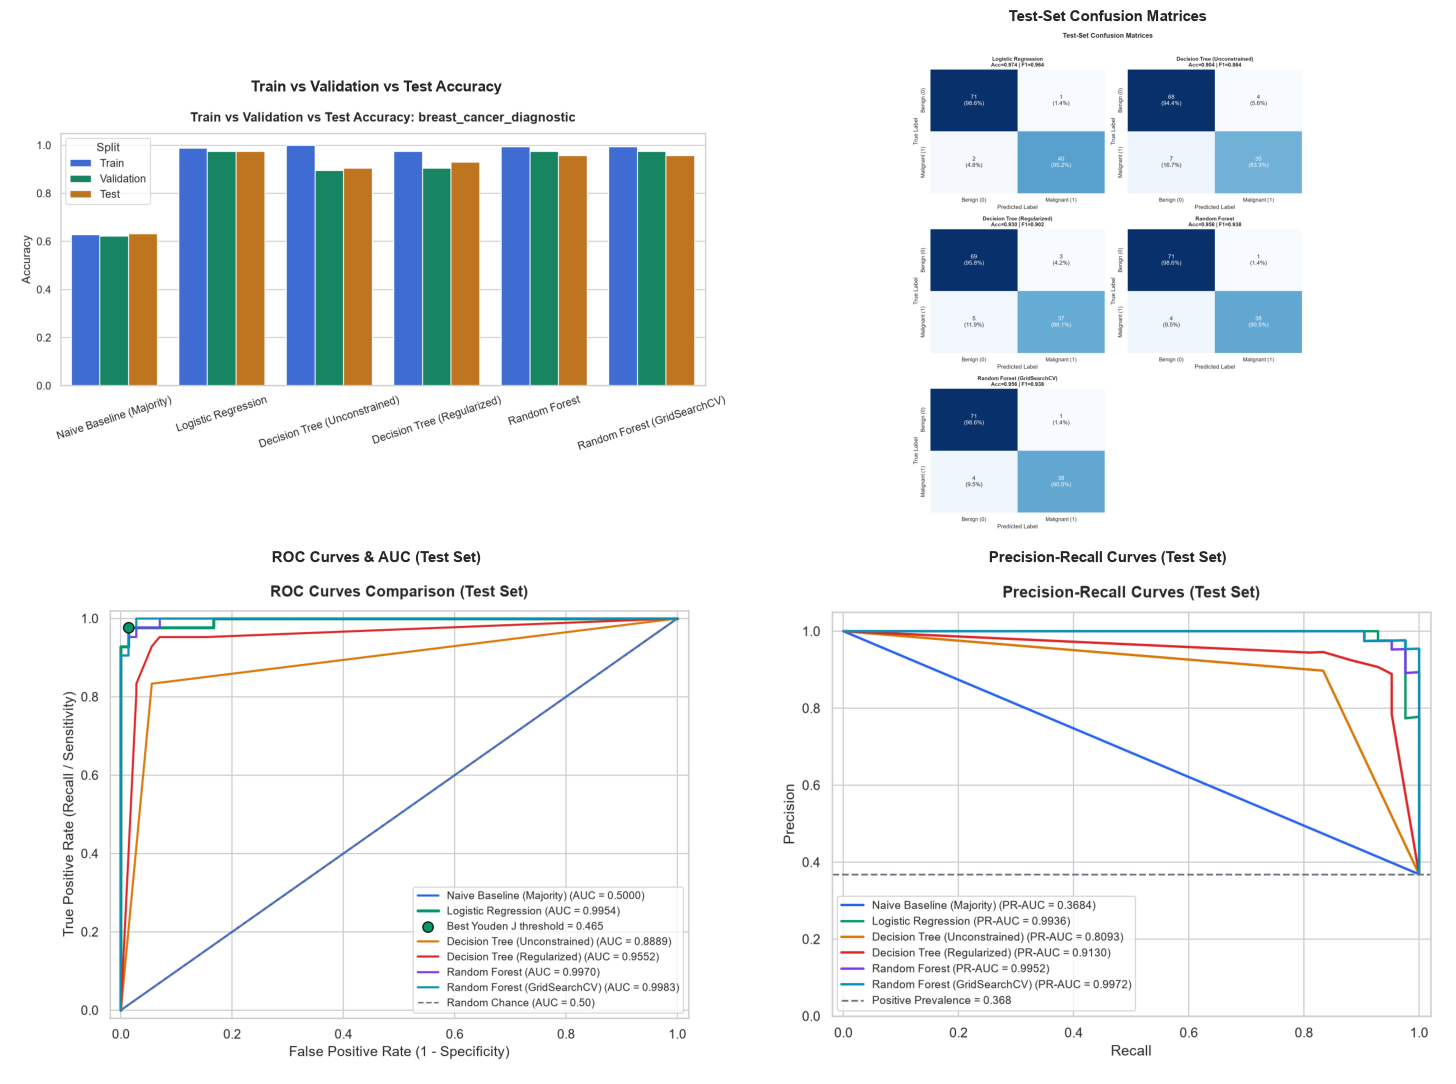

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
plot_keys = [
    ("model_comparison", "Train vs Validation vs Test Accuracy"),
    ("confusion_matrices", "Test-Set Confusion Matrices"),
    ("roc_curves", "ROC Curves & AUC (Test Set)"),
    ("precision_recall_curves", "Precision-Recall Curves (Test Set)"),
]
for ax, (key, title) in zip(axes.ravel(), plot_keys):
    img = Image.open(cls_result.plot_paths[key])
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


### Interpreting Confusion Matrices, ROC Curves, and PR Curves
- **Confusion Matrix Breakdown (Logistic Regression on Test Set):**
  - `TN = 71` (Benign correctly classified), `FP = 1` (Benign flagged as Malignant), `FN = 2` (missed Malignant cases), `TP = 40` (Malignant correctly caught).
  - **Precision = 0.9756**, **Recall (Sensitivity) = 0.9524**, **Specificity = 0.9861**.
- **ROC Curves (Bottom-Left):** Plotting True Positive Rate vs. False Positive Rate across thresholds demonstrates how closely Logistic Regression (`AUC = 0.9954`) and Random Forest (`AUC = 0.9983`) hug the top-left corner compared with the unconstrained Decision Tree (`AUC = 0.8889`) and Random Chance (`AUC = 0.50`).
- **Precision-Recall Curves (Bottom-Right):** Confirm near-1.0 precision across high recall regimes.


In [7]:
print("95% Bootstrap Confidence Intervals (Held-Out Test Set):")
for metric, ci in cls_result.bootstrap_cis.items():
    print(f"  {metric.upper():8s}: {ci['estimate']:.4f}  [95% CI: {ci['ci_low']:.4f}, {ci['ci_high']:.4f}]")

print("\nSlice-Based Error Analysis (Test Set):")
display(pd.DataFrame(cls_result.slice_analysis).round(4))

print("\nTop Predictive Features:")
display(pd.DataFrame(cls_result.feature_importances, columns=["Feature", "Importance"]).round(4))


95% Bootstrap Confidence Intervals (Held-Out Test Set):
  ACCURACY: 0.9737  [95% CI: 0.9386, 1.0000]
  F1      : 0.9639  [95% CI: 0.9136, 1.0000]
  ROC_AUC : 0.9954  [95% CI: 0.9846, 1.0000]

Slice-Based Error Analysis (Test Set):

Top Predictive Features:


,slice_feature,slice_group,n_samples,accuracy,error_rate
0,worst area,Low,38,1.0000,0.0000
1,worst area,High,38,0.9737,0.0263
2,worst area,Medium,38,0.9474,0.0526


,Feature,Importance
0,worst texture,1.3553
1,mean concave points,1.1043
2,radius error,1.0259
3,worst symmetry,0.9519
4,worst radius,0.8134
5,worst area,0.7948
6,area error,0.7822
7,worst concavity,0.7689
8,mean concavity,0.7621
9,compactness error,0.7591


### Bootstrap Uncertainty, Slice Error Analysis & Interpretability
- **95% Bootstrap Confidence Intervals:** Test Accuracy is `0.9737` (`[0.9386, 1.0000]`) and Test ROC-AUC is `0.9954` (`[0.9846, 1.0000]`).
- **Slice-Based Error Analysis:** Splitting the test set by quantiles of `worst area` shows strong accuracy across regimes: Low (`1.0000`), High (`0.9737`), Medium (`0.9474`), with borderline errors concentrated in mid-sized tumors as expected.
- **Top Predictive Feature:** `worst texture` (`|coef| = 1.3553`), alongside `mean concave points` and `radius error`.


---
## Part 2: Regression Track — Diabetes Disease Progression Dataset

Next, we explicitly apply **Linear Regression (OLS)** alongside **Decision Tree Regressor** (unconstrained vs. regularized) and **Random Forest Regressor** on a continuous outcome (`disease_progression`).


In [8]:
reg_bundle = load_builtin_regression(export_csv_path=PROJECT_ROOT / "data" / "raw" / "diabetes.csv")
reg_quality = analyze_data_quality(reg_bundle.df, reg_bundle.target_col)

print(reg_bundle.description)
print(f"Rows: {reg_quality['n_rows']}, Features: {reg_quality['n_features']}")
print(f"Target summary: {reg_quality['target_summary']}")
display(reg_bundle.df.head())


Diabetes dataset (442 patients, 10 baseline clinical measurements; continuous target disease_progression one year after baseline).
Rows: 442, Features: 10
Target summary: {'mean': 152.1335, 'std': 77.093, 'min': 25.0, 'median': 140.5, 'max': 346.0}


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,disease_progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


### Regression Dataset Overview
- Contains **442 patients** and **10 baseline physiological features** (`age`, `sex`, `bmi`, `bp`, and serum metrics `s1`–`s6`), with pre-encoded `sex` preserved numerically.
- Continuous target `disease_progression` ranges from `25.0` to `346.0` (mean `152.13`, std `77.09`) with 0 missing values and 0 duplicates.


In [9]:
reg_result = run_experiment(
    reg_bundle,
    output_dir=PROJECT_ROOT / "outputs" / "regression",
    random_state=42,
    tune_best=True,
)
display(reg_result.comparison_df.round(4))
print(f"Best regression model selected on Validation: {reg_result.best_model_name}")

print("\n95% Bootstrap Confidence Intervals (Held-Out Test Set):")
for metric, ci in reg_result.bootstrap_cis.items():
    print(f"  {metric.upper():5s}: {ci['estimate']:.4f}  [95% CI: {ci['ci_low']:.4f}, {ci['ci_high']:.4f}]")


Best regression model selected on Validation: Linear Regression (OLS)

95% Bootstrap Confidence Intervals (Held-Out Test Set):
  R2   : 0.4464  [95% CI: 0.2582, 0.5851]
  RMSE : 54.1564  [95% CI: 46.8169, 61.3594]
  MAE  : 42.9245  [95% CI: 36.2444, 50.0168]


,key,model,train_r2,val_r2,test_r2,val_rmse,test_rmse,val_mae,test_mae,cv_r2_mean,cv_r2_std,overfit_gap,train_time_sec
0,naive_baseline,Naive Baseline (Mean),0.0000,-0.0443,-0.0031,75.6392,72.9002,64.1288,63.5314,-0.0231,0.0173,0.0443,0.0054
1,linear_regression,Linear Regression (OLS),0.5203,0.5216,0.4464,51.1937,54.1564,42.9389,42.9245,0.4629,0.0887,-0.0014,0.0167
2,decision_tree_unconstrained,Decision Tree (Unconstrained),1.0000,0.2025,-0.2764,66.1011,82.2349,50.5506,65.5506,-0.2859,0.3288,0.7975,0.0050
3,decision_tree_regularized,Decision Tree (Regularized),0.6137,0.3196,0.3113,61.0539,60.4061,48.7993,48.5994,0.1981,0.0824,0.2940,0.0041
4,random_forest,Random Forest,0.8816,0.4704,0.4384,53.8682,54.5466,43.9619,44.5518,0.3734,0.0812,0.4113,0.1803
5,random_forest_tuned,Random Forest (GridSearchCV),0.6862,0.4700,0.4571,53.8847,53.6337,43.2850,43.2546,0.3968,0.0779,0.2162,0.1832


### Regression Model Comparison & Overfitting Diagnostics
- **Selected Winner (by Validation R²):** **Linear Regression (OLS)** (`Val R² = 0.5216`, `Val RMSE = 51.19`, `Test R² = 0.4464`, `Test RMSE = 54.16`).
- **Textbook Overfitting Example:** The **Unconstrained Decision Tree Regressor** achieves a perfect `Train R² = 1.0000`, yet crashes to `Val R² = 0.2025` and `Test R² = -0.2764` (`Test RMSE = 82.23`) — performing worse than simply predicting the mean!
- **Regularization & Ensembling:** Restricting depth (`max_depth=4`) recovers positive generalization (`Test R² = 0.3113`), while **Random Forest (GridSearchCV)** cuts the overfit gap from `0.4113` down to `0.2162` and reaches `Test R² = 0.4571` (`Test RMSE = 53.63`).


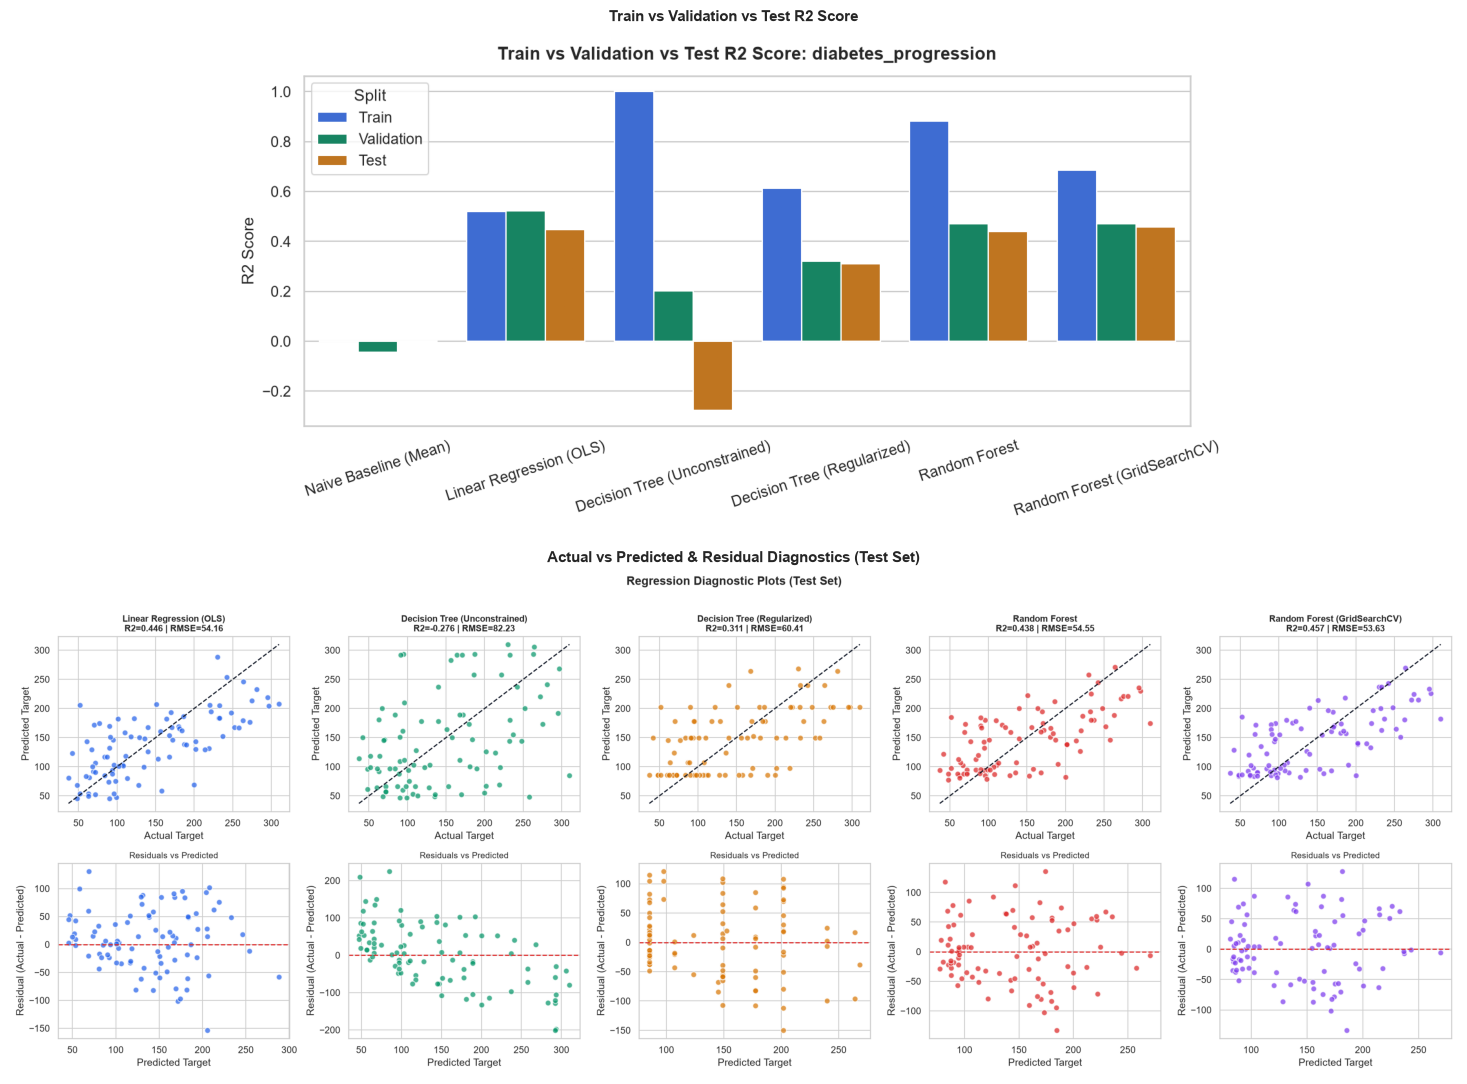

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
for ax, (key, title) in zip(
    axes,
    [
        ("model_comparison", "Train vs Validation vs Test R2 Score"),
        ("regression_diagnostics", "Actual vs Predicted & Residual Diagnostics (Test Set)"),
    ],
):
    img = Image.open(reg_result.plot_paths[key])
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


### Residual & Generalization Insights
- The **Actual vs. Predicted** plots show Linear Regression and Random Forest predictions aligning tightly around the $y = x$ reference line, whereas the regularized tree outputs discrete horizontal step bands and the unconstrained tree scatters erratically.
- **Residuals vs. Predicted** remain centered symmetrically near `0` across Linear Regression and Random Forest, confirming well-calibrated error behavior without major systemic bias.


---
## Conclusion & Key Takeaways

This project demonstrates end-to-end supervised predictive modeling and rigorous evaluation:
1. **Linear / Logistic Regression vs. Decision Trees vs. Random Forest:**
   - **Logistic Regression** (classification) and **Linear Regression** (regression) won model selection on the validation split (`Val ROC-AUC = 0.9957` and `Val R² = 0.5216`), showing that well-regularized linear models excel on clean, low-to-moderate-dimensional tabular problems with minimal overfitting and millisecond training speed.
   - **Decision Trees** require explicit depth/leaf constraints (`max_depth=4, min_samples_leaf=5`) — without regularization, both classification and regression trees hit `1.0000` training scores while degrading sharply on unseen data (`Test R² = -0.2764` on regression).
   - **Random Forests** dramatically reduce variance over single trees and achieved the highest held-out test ROC-AUC (`0.9983` on Breast Cancer) and highest held-out test $R^2$ (`0.4571` on Diabetes) after cross-validated hyperparameter tuning.
2. **Leakage-Free Preprocessing & Statistical Rigor:** Always splitting Train / Validation / Test prior to fitting imputers or scalers, validating across 5-fold CV, and reporting Confusion Matrices, ROC/PR curves, 95% Bootstrap CIs, and slice error analysis yields trustworthy, production-ready evaluations.
